
# Exploratory Data Analysis on Superstore Retail Sales

## 1. Project Introduction

This project focuses on analyzing retail sales data to identify
customer purchasing patterns, monthly sales trends, product
category performance, and discount sensitivity.

The analysis is performed using Python and its data analysis
and visualization libraries.

### Objectives
- Perform data cleaning and preprocessing.
- Analyze customer purchase volume.
- Identify monthly sales seasonality.
- Evaluate category-wise revenue and profit.
- Investigate the relationship between discounts and profit.
- Generate at least five executive business takeaways.

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Dataset
Superstore Retail Sales Dataset


In [1]:

# 2. Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

# Display numbers with two decimal places
pd.set_option("display.float_format", "{:.2f}".format)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# 3. Load the Dataset

df = pd.read_csv("superstore_sales.csv")

# Display first five records
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.00,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


In [3]:

# Check dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 10800
Number of Columns: 21


In [4]:

# Display all column names

df.columns.tolist()


['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']


## 2. Initial Data Exploration

In this section, the dataset is examined to understand
its structure, data types, missing values, and
statistical characteristics.


In [5]:

# Display dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

In [6]:

# Statistical summary of numerical columns

df.describe()


,Postal Code,Sales,Quantity,Discount,Profit
count,9983.00,9994.00,9994.00,9994.00,9994.00
mean,55245.23,229.86,3.79,0.16,28.66
std,32038.72,623.25,2.23,0.21,234.26
min,1040.00,0.44,1.00,0.00,-6599.98
25%,23223.00,17.28,2.00,0.00,1.73
50%,57103.00,54.49,3.00,0.20,8.67
75%,90008.00,209.94,5.00,0.20,29.36
max,99301.00,22638.48,14.00,0.80,8399.98


In [7]:

# Check missing values

missing_values = df.isnull().sum()

missing_values


Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

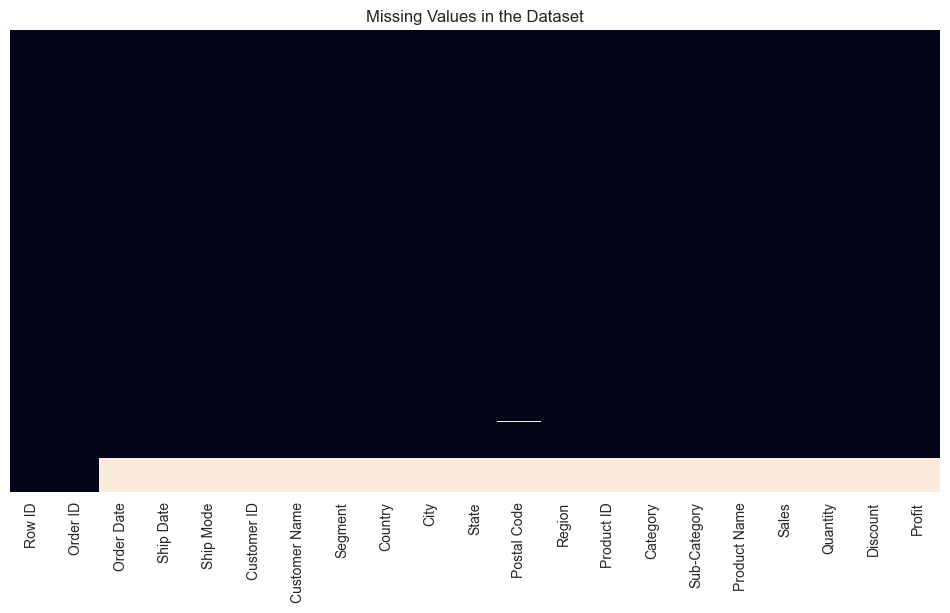

In [8]:

# Visualize missing values

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in the Dataset")

plt.show()



## 3. Data Cleaning and Preprocessing

Data cleaning is performed to ensure that the dataset
contains valid and reliable sales records.

The cleaning process includes:
- Removing incomplete sales records.
- Checking duplicate records.
- Converting date columns.
- Creating additional date-related columns.


In [9]:

# Create a copy of the original dataset

df_clean = df.copy()

print("Original Dataset Shape:", df.shape)


Original Dataset Shape: (10800, 21)


In [10]:

# Remove records missing essential sales information

df_clean = df_clean.dropna(
    subset=[
        "Order ID",
        "Order Date",
        "Sales",
        "Profit",
        "Category"
    ]
)

print("Cleaned Dataset Shape:", df_clean.shape)


Cleaned Dataset Shape: (9994, 21)


In [11]:

# Check duplicate records

duplicate_count = df_clean.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)


Number of Duplicate Records: 0


In [12]:

# Check duplicate Row IDs

print(
    "Duplicate Row IDs:",
    df_clean["Row ID"].duplicated().sum()
)


Duplicate Row IDs: 0


In [13]:

# Convert date columns to datetime format

df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    errors="coerce"
)

# Check date range

print("Minimum Order Date:", df_clean["Order Date"].min())

print("Maximum Order Date:", df_clean["Order Date"].max())


Minimum Order Date: 2015-01-03 00:00:00
Maximum Order Date: 2018-12-30 00:00:00


In [14]:

# Extract year, month, and month name

df_clean["Year"] = df_clean["Order Date"].dt.year

df_clean["Month"] = df_clean["Order Date"].dt.month

df_clean["Month Name"] = df_clean["Order Date"].dt.month_name()

df_clean["Year-Month"] = df_clean["Order Date"].dt.to_period("M")

# Display cleaned dataset

df_clean.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91,2017,11,November,2017-11
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58,2017,11,November,2017-11
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.00,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87,2017,6,June,2017-06
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03,2016,10,October,2016-10
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52,2016,10,October,2016-10



## 4. Customer Purchase Volume Analysis

This section analyzes customer purchasing behavior,
order volume, and customer segments to identify
important sales patterns.


In [15]:

# Total unique customers

total_customers = df_clean["Customer ID"].nunique()

# Total unique orders

total_orders = df_clean["Order ID"].nunique()

# Total products sold

total_quantity = df_clean["Quantity"].sum()

print("Total Customers:", total_customers)

print("Total Orders:", total_orders)

print("Total Quantity Sold:", total_quantity)


Total Customers: 793
Total Orders: 5009
Total Quantity Sold: 37873.0


In [16]:

# Group sales by customer segment

segment_analysis = df_clean.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

segment_analysis


,Segment,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,Consumer,1161401.34,134119.21,2586,19521.00
1,Corporate,706146.37,91979.13,1514,11608.00
2,Home Office,429653.15,60298.68,909,6744.00


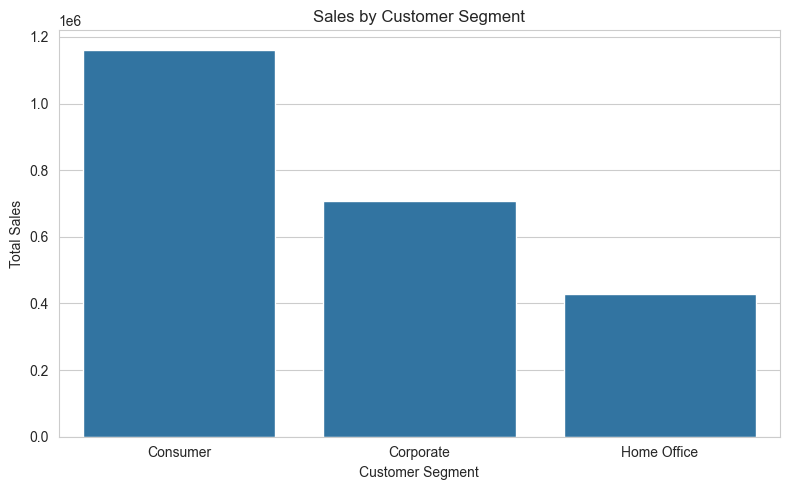

In [17]:

# Visualize sales by customer segment

plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Sales"
)

plt.title("Sales by Customer Segment")

plt.xlabel("Customer Segment")

plt.ylabel("Total Sales")

plt.tight_layout()

plt.show()



## 5. Monthly Sales Seasonality Analysis

This section analyzes monthly sales trends to
identify seasonal patterns and periods of high
or low sales performance.


In [18]:

# Group sales and profit by year-month

monthly_sales = df_clean.groupby("Year-Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

# Convert period values to strings for plotting

monthly_sales["Year-Month"] = (
    monthly_sales["Year-Month"].astype(str)
)

monthly_sales.head()


,Year-Month,Total_Sales,Total_Profit
0,2015-01,14236.90,2450.19
1,2015-02,4519.89,862.31
2,2015-03,55691.01,498.73
3,2015-04,28295.35,3488.84
4,2015-05,23648.29,2738.71


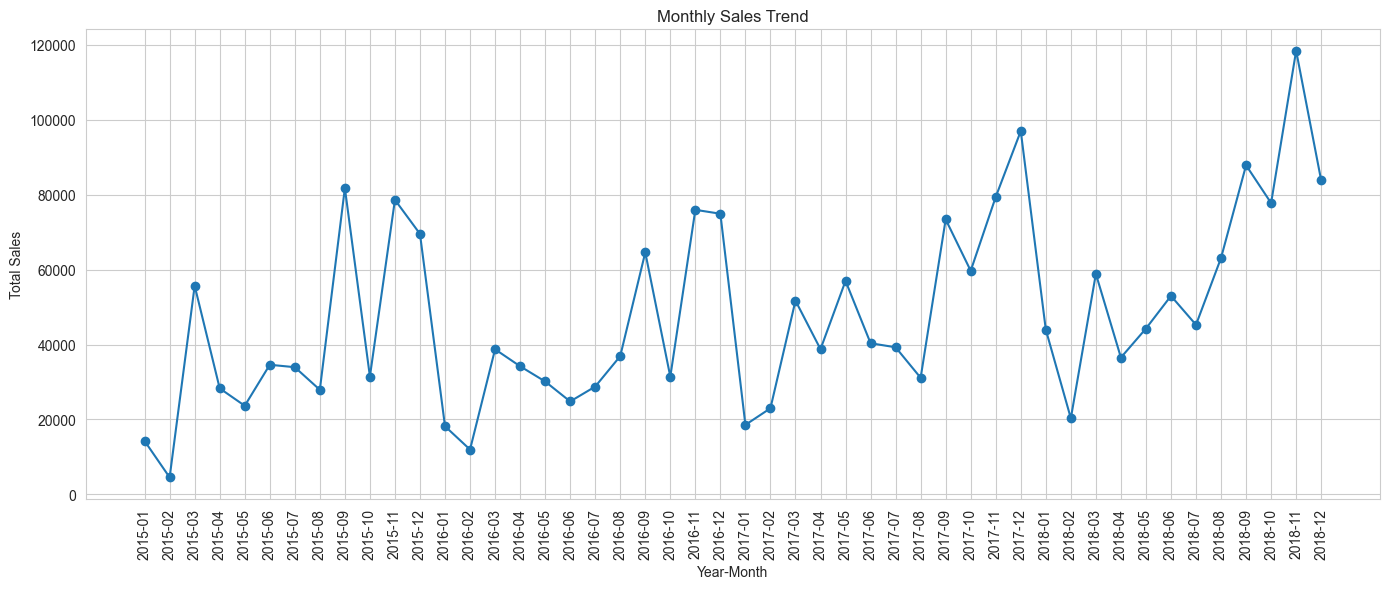

In [19]:

# Monthly sales trend visualization

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")

plt.xlabel("Year-Month")

plt.ylabel("Total Sales")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()


In [20]:

# Identify highest and lowest sales months

highest_sales_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

lowest_sales_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmin()
]

print("Highest Sales Month:")

print(highest_sales_month)

print("\nLowest Sales Month:")

print(lowest_sales_month)


Highest Sales Month:
Year-Month       2018-11
Total_Sales    118447.82
Total_Profit     9690.10
Name: 46, dtype: object

Lowest Sales Month:
Year-Month      2015-02
Total_Sales     4519.89
Total_Profit     862.31
Name: 1, dtype: object



## 6. Category-Wise Revenue and Profit Analysis

This section compares product categories based on
revenue, profit, quantity sold, and average discount.

The objective is to identify the most profitable
and highest-revenue product categories.


In [21]:

# Category-wise sales and profit analysis

category_analysis = df_clean.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
).reset_index()

category_analysis


,Category,Total_Sales,Total_Profit,Total_Quantity,Average_Discount
0,Furniture,741999.80,18451.27,8028.00,0.17
1,Office Supplies,719047.03,122490.80,22906.00,0.16
2,Technology,836154.03,145454.95,6939.00,0.13


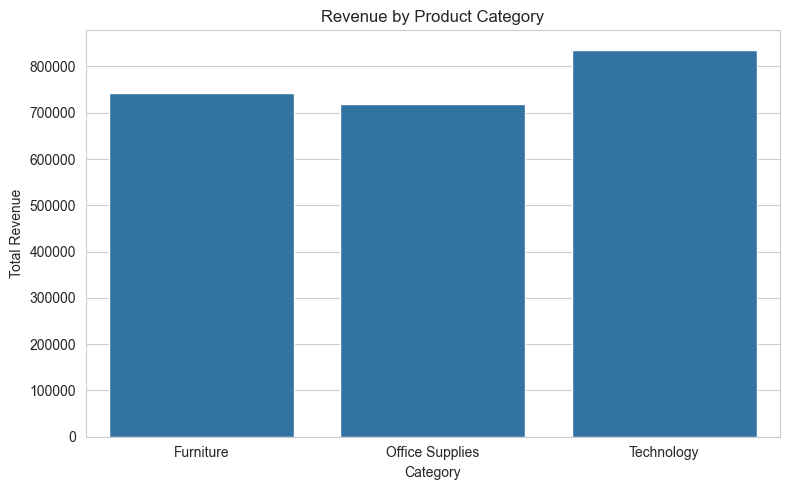

In [22]:

# Revenue by product category

plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales"
)

plt.title("Revenue by Product Category")

plt.xlabel("Category")

plt.ylabel("Total Revenue")

plt.tight_layout()

plt.show()


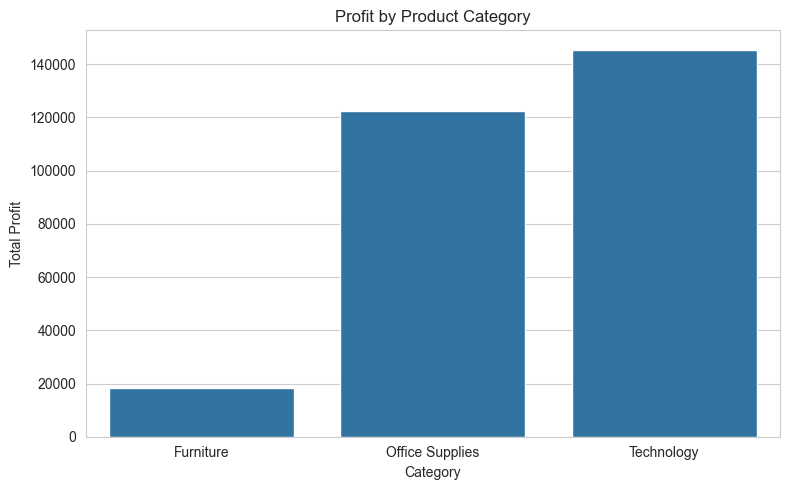

In [23]:

# Profit by product category

plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Profit"
)

plt.title("Profit by Product Category")

plt.xlabel("Category")

plt.ylabel("Total Profit")

plt.tight_layout()

plt.show()


In [24]:

# Identify category with highest revenue

highest_revenue_category = category_analysis.loc[
    category_analysis["Total_Sales"].idxmax()
]

# Identify category with highest profit

highest_profit_category = category_analysis.loc[
    category_analysis["Total_Profit"].idxmax()
]

print("Highest Revenue Category:")

print(highest_revenue_category)

print("\nHighest Profit Category:")

print(highest_profit_category)


Highest Revenue Category:
Category            Technology
Total_Sales          836154.03
Total_Profit         145454.95
Total_Quantity         6939.00
Average_Discount          0.13
Name: 2, dtype: object

Highest Profit Category:
Category            Technology
Total_Sales          836154.03
Total_Profit         145454.95
Total_Quantity         6939.00
Average_Discount          0.13
Name: 2, dtype: object



## 7. Discount Sensitivity Analysis

This section investigates the relationship between
discounts and profitability.

The analysis uses a scatter plot to identify
patterns between discount percentages and profit.


In [25]:

# Group sales by discount level

discount_analysis = df_clean.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

discount_analysis


,Discount,Total_Sales,Total_Profit,Average_Profit,Total_Quantity
0,0.00,1087908.47,320987.60,66.90,18267.00
1,0.10,54369.35,9029.18,96.06,373.00
2,0.15,27558.52,1418.99,27.29,198.00
3,0.20,764594.37,90337.31,24.70,13660.00
4,0.30,103226.65,-10369.28,-45.68,849.00
5,0.32,14493.46,-2391.14,-88.56,105.00
6,0.40,116417.78,-23057.05,-111.93,786.00
7,0.45,5484.97,-2493.11,-226.65,45.00
8,0.50,58918.54,-20506.43,-310.70,241.00
9,0.60,6644.70,-5944.66,-43.08,501.00


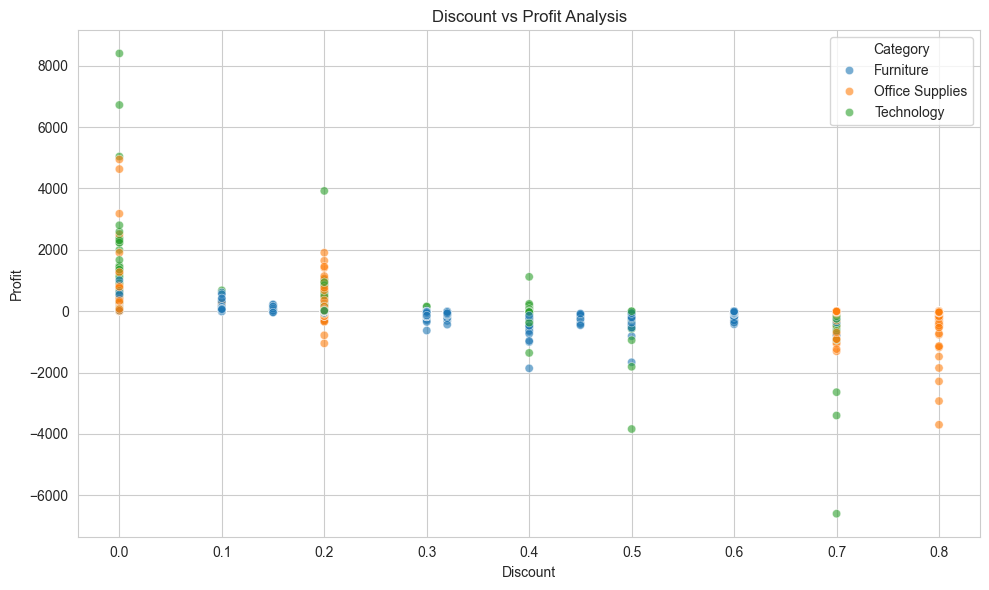

In [26]:

# Discount vs Profit scatter plot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.title("Discount vs Profit Analysis")

plt.xlabel("Discount")

plt.ylabel("Profit")

plt.tight_layout()

plt.show()


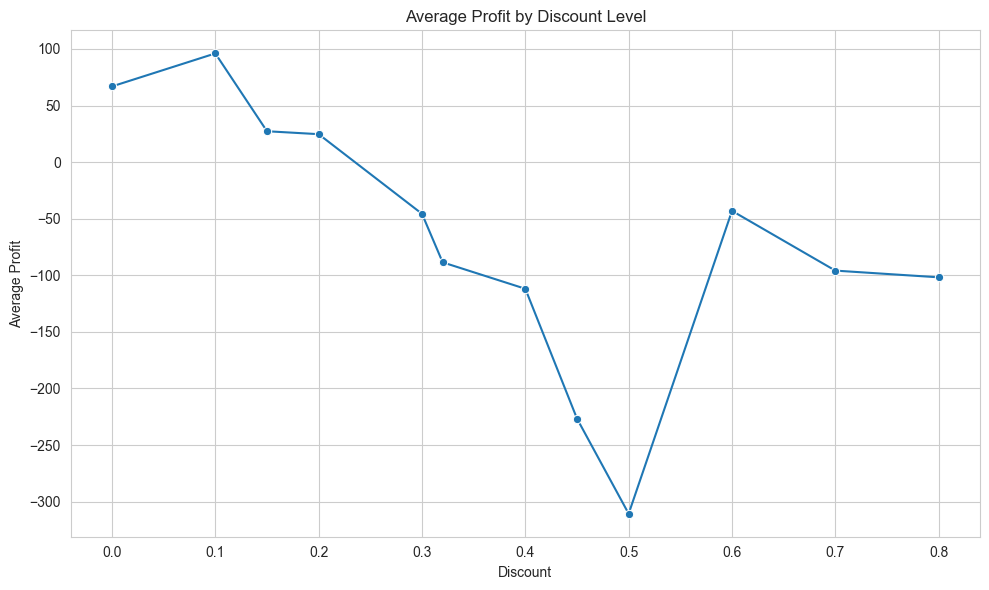

In [27]:

# Plot average profit by discount level

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=discount_analysis,
    x="Discount",
    y="Average_Profit",
    marker="o"
)

plt.title("Average Profit by Discount Level")

plt.xlabel("Discount")

plt.ylabel("Average Profit")

plt.tight_layout()

plt.show()



## 8. Regional Sales Analysis

This section analyzes sales and profit across
different geographical regions.

The objective is to identify strong-performing
and underperforming regions.


In [28]:

# Analyze sales by region

region_analysis = df_clean.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

region_analysis


,Region,Total_Sales,Total_Profit,Total_Orders
0,Central,501239.89,39706.36,1175
1,East,678781.24,91522.78,1401
2,South,391721.91,46749.43,822
3,West,725457.82,108418.45,1611


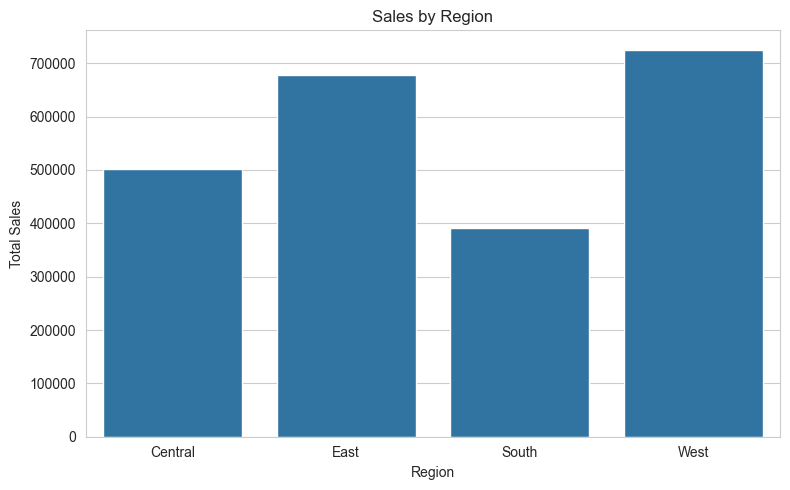

In [29]:

# Regional sales chart

plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Sales"
)

plt.title("Sales by Region")

plt.xlabel("Region")

plt.ylabel("Total Sales")

plt.tight_layout()

plt.show()



## 9. Executive Business Takeaways

The following insights summarize the important
findings obtained from the exploratory data analysis.


In [30]:

# Calculate important business metrics

total_sales = df_clean["Sales"].sum()

total_profit = df_clean["Profit"].sum()

total_orders = df_clean["Order ID"].nunique()

total_customers = df_clean["Customer ID"].nunique()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))

print("Total Profit:", round(total_profit, 2))

print("Total Orders:", total_orders)

print("Total Customers:", total_customers)

print("Profit Margin:", round(profit_margin, 2), "%")


Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Profit Margin: 12.47 %


## Executive Business Takeaways

### 1. Customer Purchase Volume
The customer segment analysis identifies the segment contributing the highest sales and order volume. This information can help the business improve customer engagement and marketing strategies.

### 2. Monthly Sales Seasonality
The monthly sales analysis identifies periods of high and low demand. Understanding these patterns can support better inventory planning and promotional activities.

### 3. Category-Wise Revenue and Profitability
The category analysis highlights differences in revenue and profitability across product categories. Businesses should evaluate both sales and profit when making product-related decisions.

### 4. Discount Sensitivity
The discount analysis reveals the relationship between discount levels and profitability. Reviewing discount strategies can help reduce unnecessary losses and improve profit margins.

### 5. Regional Sales Performance
The regional analysis identifies geographical areas contributing the most revenue and profit. These insights can help businesses allocate resources more effectively.

## 10. Conclusion

The Exploratory Data Analysis of the Superstore Retail Sales dataset provided insights into customer purchasing behavior, monthly sales trends, product category performance, and discount sensitivity.

The analysis was performed using Python, Pandas, NumPy, Matplotlib, and Seaborn.

Data cleaning and preprocessing ensured that the analysis was based on valid sales records.

The visualizations and business findings help identify sales patterns, profitability differences, and opportunities for improving business performance.

This project demonstrates the practical application of data analysis techniques in solving real-world business problems.